In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
np.random.seed(42)


In [2]:

import pandas as pd
from pathlib import Path

# Dataset folder
DATA_DIR = Path("../data/airline_clustering")

# Load CSV files
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

# Combine both datasets
df = pd.concat([train, test], ignore_index=True)

# Remove ID columns if present
df.drop(columns=["Unnamed: 0", "id"], errors="ignore", inplace=True)

print("Combined shape:", df.shape)
display(df.head())


Train shape: (103904, 25)
Test shape: (25976, 25)
Combined shape: (129880, 23)


,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [3]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

if "satisfaction" in df.columns:
    print("\nPassenger satisfaction counts:")
    print(df["satisfaction"].value_counts())


Dataset shape: (129880, 23)

Column names:
['Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'satisfaction']

Data types:


,Data Type
Gender,object
Customer Type,object
Age,int64
Type of Travel,object
Class,object
Flight Distance,int64
Inflight wifi service,int64
Departure/Arrival time convenient,int64
Ease of Online booking,int64
Gate location,int64



Missing values:


,Missing Values
Gender,0
Customer Type,0
Age,0
Type of Travel,0
Class,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0
Ease of Online booking,0
Gate location,0



Duplicate rows: 0

Passenger satisfaction counts:
satisfaction
neutral or dissatisfied    73452
satisfied                  56428
Name: count, dtype: int64


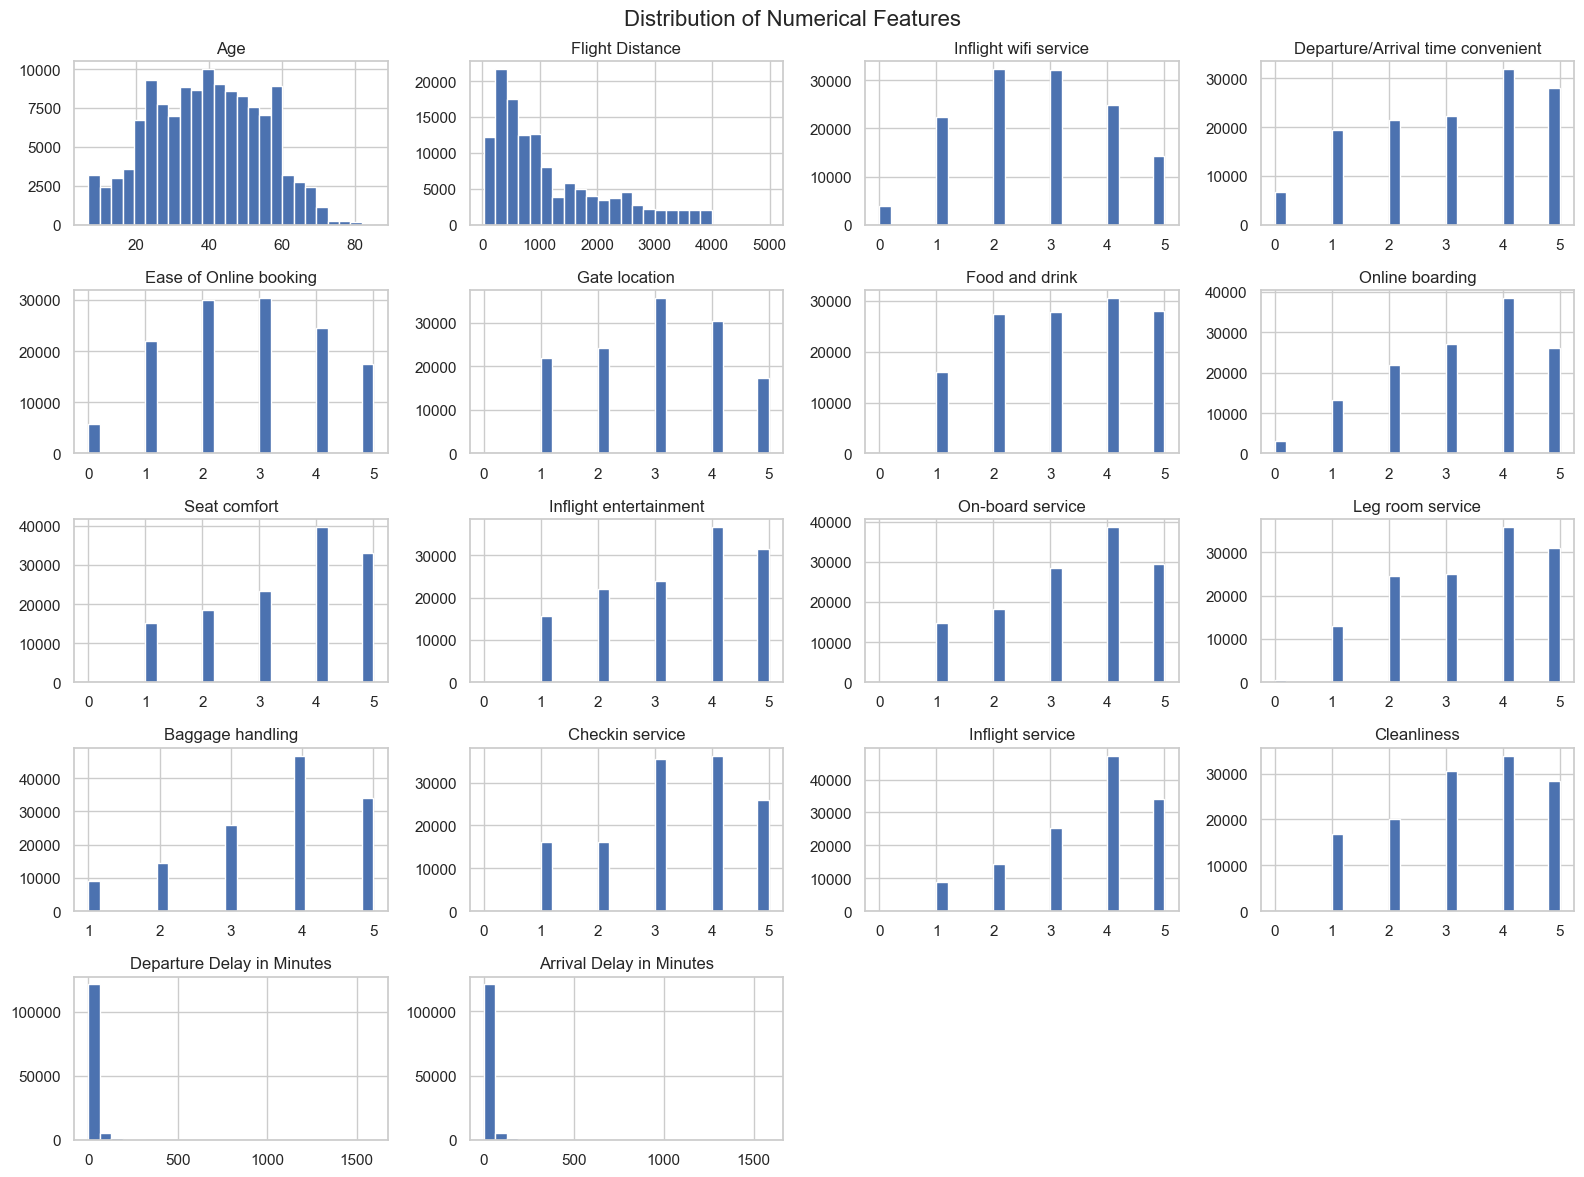

In [4]:
# Select columns containing numerical data
numeric_cols = df.select_dtypes(include=np.number).columns

# Plot histograms to understand numerical feature distributions
df[numeric_cols].hist(figsize=(16, 12), bins=25)

# Add a title to the overall figure
plt.suptitle("Distribution of Numerical Features", fontsize=16)

# Adjust spacing to prevent overlapping plots
plt.tight_layout()

# Display the histograms
plt.show()

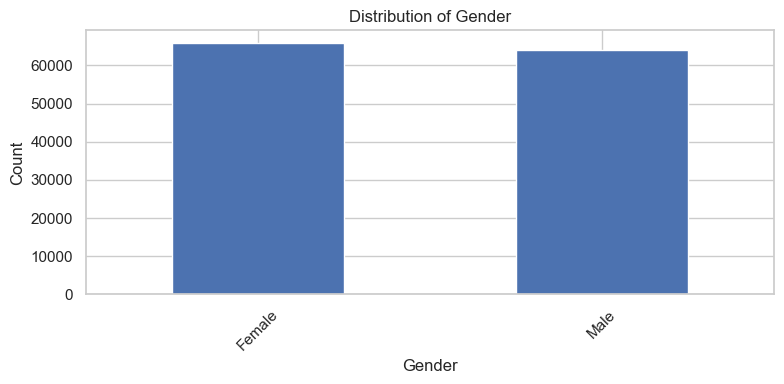

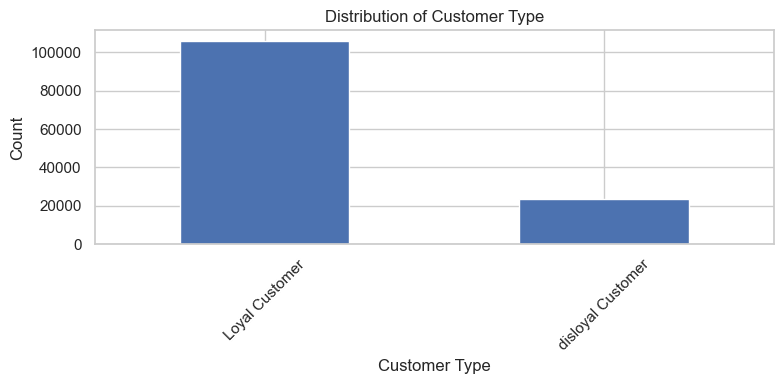

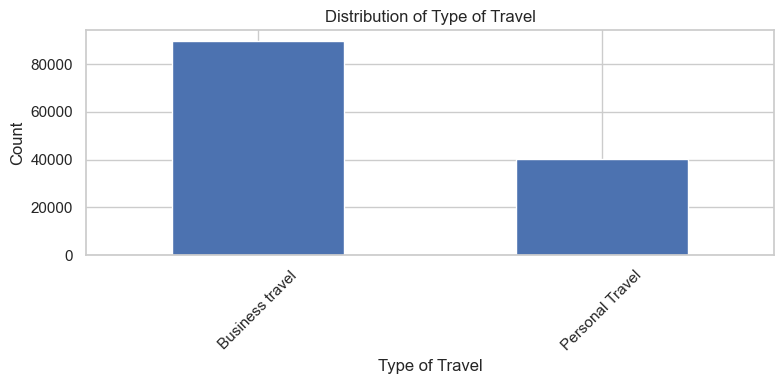

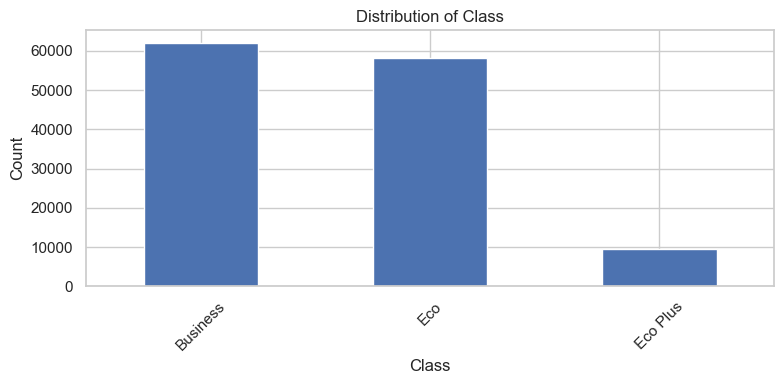

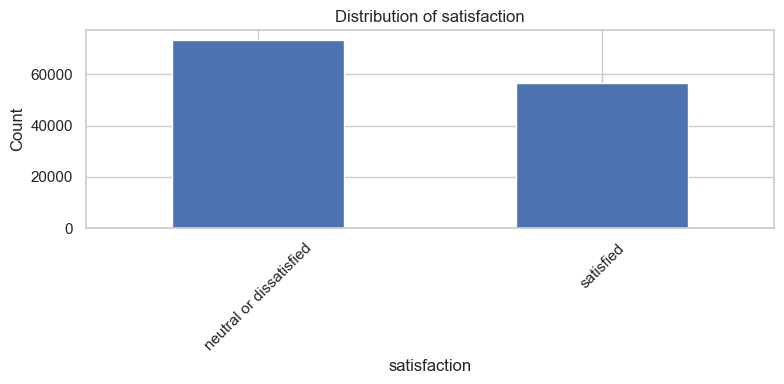

In [5]:
# Select columns containing categorical data
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns

# Plot a bar chart for each categorical column
for col in categorical_cols:

    # Create a new figure
    plt.figure(figsize=(8, 4))

    # Count each category and plot the most common 15
    df[col].value_counts().head(15).plot(kind="bar")

    # Add chart labels
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")

    # Rotate labels for readability
    plt.xticks(rotation=45)

    # Adjust the chart layout
    plt.tight_layout()

    # Display the chart
    plt.show()

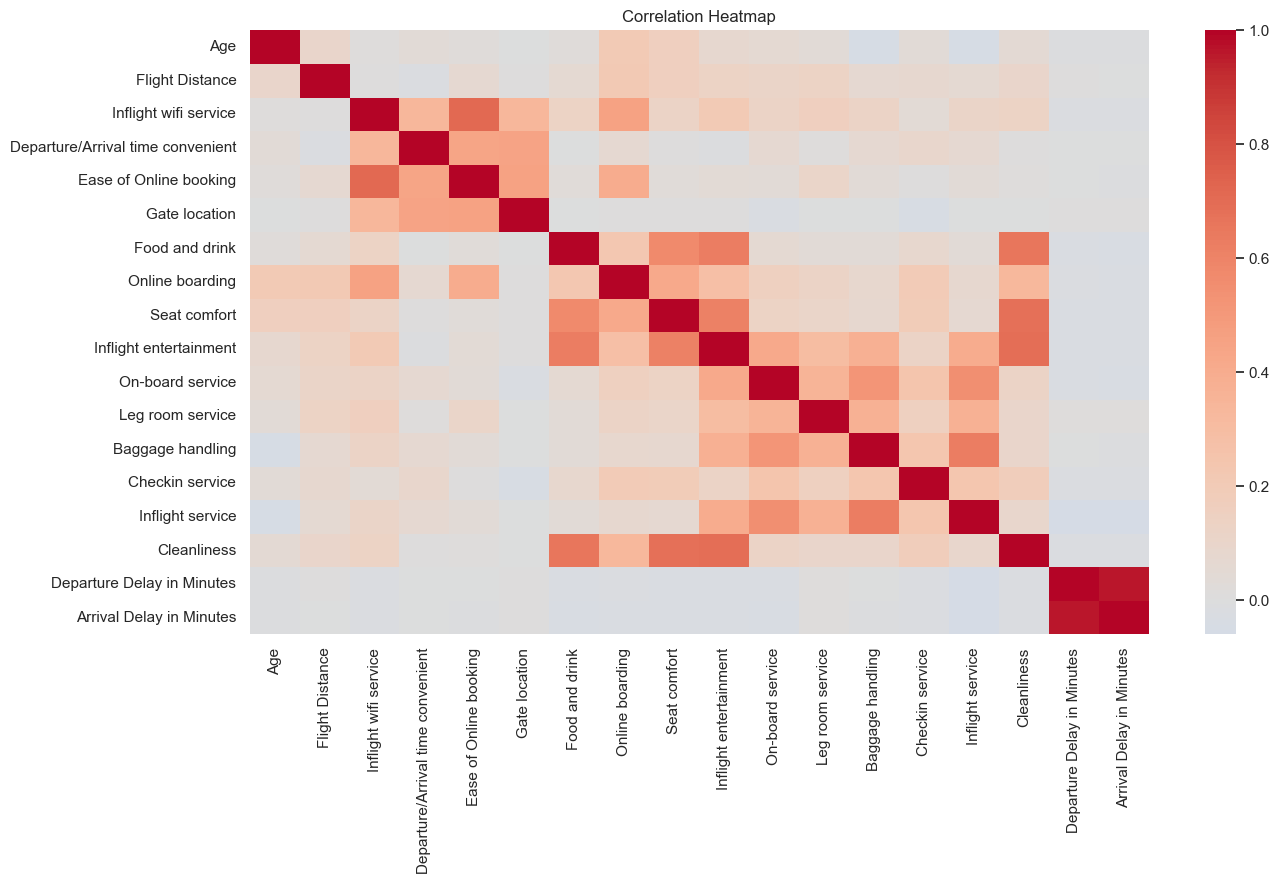

In [6]:
# Select numerical columns and calculate their correlations
correlation_matrix = df.select_dtypes(
    include=np.number
).corr()

# Create the heatmap
plt.figure(figsize=(14, 9))

# Display correlations using colors
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

# Add a title
plt.title("Correlation Heatmap")

# Adjust the layout and display the graph
plt.tight_layout()
plt.show()

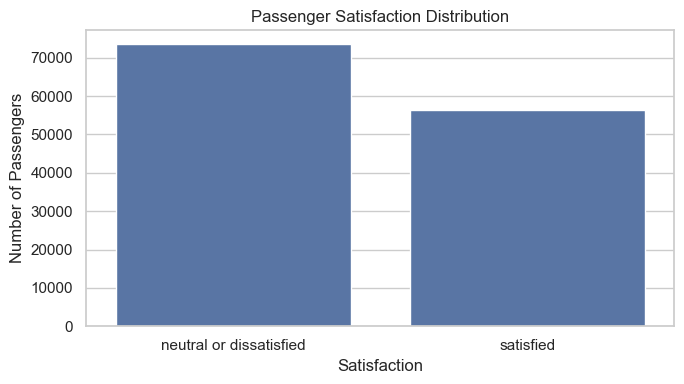

In [7]:
# Check whether the satisfaction column exists
if "satisfaction" in df.columns:

    # Create a bar chart of satisfaction categories
    plt.figure(figsize=(7, 4))
    sns.countplot(data=df, x="satisfaction")

    # Add chart labels
    plt.title("Passenger Satisfaction Distribution")
    plt.xlabel("Satisfaction")
    plt.ylabel("Number of Passengers")

    # Display the chart
    plt.tight_layout()
    plt.show()

In [8]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Save satisfaction separately for later interpretation
# It must not be included in the clustering features
satisfaction = (
    df["satisfaction"].copy()
    if "satisfaction" in df.columns
    else None
)

# Remove satisfaction from the input features
X_df = df.drop(
    columns=["satisfaction"],
    errors="ignore"
).copy()

# Replace common invalid entries with missing values
X_df.replace(["?", "NA", "N/A", ""], np.nan, inplace=True)

# Remove columns containing only missing values
X_df.dropna(axis=1, how="all", inplace=True)

# Identify numerical columns
num_cols = X_df.select_dtypes(include=np.number).columns

# Fill missing numerical values using each column's median
X_df[num_cols] = X_df[num_cols].fillna(
    X_df[num_cols].median()
)

# Identify categorical columns
cat_cols = X_df.select_dtypes(
    include=["object", "category"]
).columns

# Fill missing categorical values with the most frequent category
for col in cat_cols:
    if X_df[col].notna().any():
        X_df[col] = X_df[col].fillna(
            X_df[col].mode().iloc[0]
        )

# Display the cleaned data information
print("Cleaned feature shape:", X_df.shape)
print("Remaining missing values:", X_df.isnull().sum().sum())

Cleaned feature shape: (129880, 22)
Remaining missing values: 0


In [9]:
# Convert categorical columns into numerical indicator columns
# drop_first=True avoids one redundant indicator per category
X_encoded = pd.get_dummies(
    X_df,
    drop_first=True,
    dtype=int
)

# Display the dimensions after encoding
print("Shape after encoding:", X_encoded.shape)

# Display the first five encoded rows
display(X_encoded.head())

Shape after encoding: (129880, 23)


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender_Male,Customer Type_disloyal Customer,Type of Travel_Personal Travel,Class_Eco,Class_Eco Plus
0,13,460,3,4,3,1,5,3,5,5,...,4,5,5,25,18.0,1,0,1,0,1
1,25,235,3,2,3,3,1,3,1,1,...,1,4,1,1,6.0,1,1,0,0,0
2,26,1142,2,2,2,2,5,5,5,5,...,4,4,5,0,0.0,0,0,0,0,0
3,25,562,2,5,5,5,2,2,2,2,...,1,4,2,11,9.0,0,0,0,0,0
4,61,214,3,3,3,3,4,5,5,3,...,3,3,3,0,0.0,1,0,0,0,0


In [10]:
# Create a StandardScaler object
scaler = StandardScaler()

# Transform features so each has approximately zero mean
# and unit variance
X_scaled = scaler.fit_transform(X_encoded)

# Check the dimensions after scaling
print("Scaled data shape:", X_scaled.shape)

# Check that there are no infinite or invalid numerical values
print("All values finite:", np.isfinite(X_scaled).all())

Scaled data shape: (129880, 23)
All values finite: True


In [11]:
# Use at most 10,000 records to speed up repeated experiments
SAMPLE_SIZE = min(10000, len(X_scaled))

# Create a reproducible random number generator
rng = np.random.RandomState(42)

# Select random row indices without replacement
sample_indices = rng.choice(
    len(X_scaled),
    size=SAMPLE_SIZE,
    replace=False
)

# Create the sample used for model selection and visualization
X_sample = X_scaled[sample_indices]

# Display the sample dimensions
print("Sample shape:", X_sample.shape)

Sample shape: (10000, 23)


Explained variance ratio: [0.17461347 0.10512012]
Total variance explained: 0.279733586678121


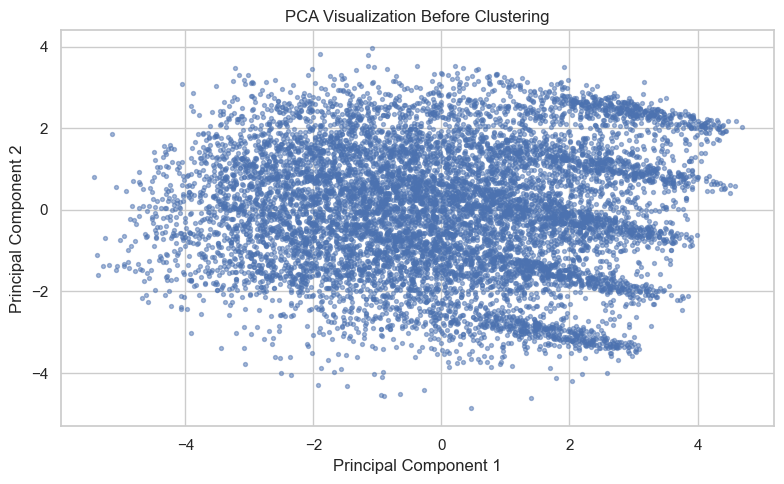

In [12]:
# Reduce the scaled features to two principal components
pca = PCA(n_components=2, random_state=42)

# Transform the sample into two-dimensional coordinates
X_pca = pca.fit_transform(X_sample)

# Display the amount of variance explained by each component
print("Explained variance ratio:", pca.explained_variance_ratio_)

# Display the total variance explained by the two components
print("Total variance explained:", pca.explained_variance_ratio_.sum())

# Plot the data in two dimensions
plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    s=8,
    alpha=0.5
)

# Add labels and title
plt.title("PCA Visualization Before Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

# Display the graph
plt.tight_layout()
plt.show()

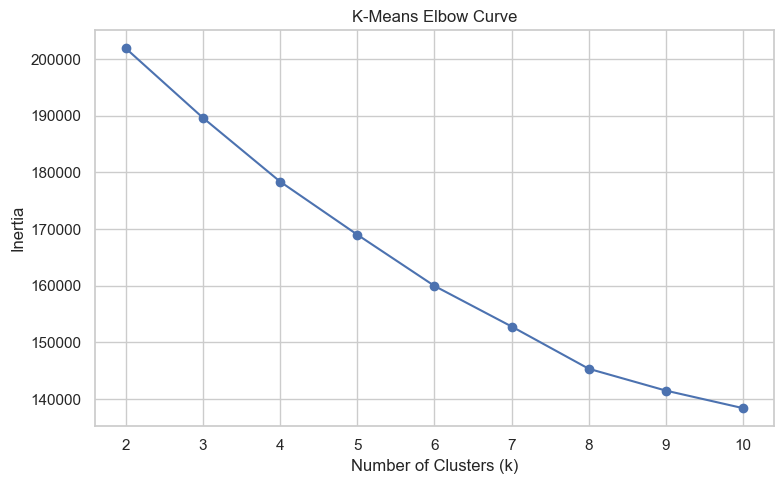

In [13]:
# Store the inertia values for different cluster counts
inertias = []

# Test cluster counts from 2 to 10
k_values = range(2, 11)

for k in k_values:

    # Create the K-Means model
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Fit the model to the sample
    model.fit(X_sample)

    # Store inertia, the sum of squared distances to cluster centers
    inertias.append(model.inertia_)

# Plot inertia against the number of clusters
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")

# Add chart labels
plt.title("K-Means Elbow Curve")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))

# Display the graph
plt.tight_layout()
plt.show()

In [14]:
# Create an empty list to store evaluation results
results = []

# Compare cluster counts from 2 to 7
for k in range(2, 8):

    # Create a K-Means model for the current k
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Fit the model and obtain cluster assignments
    labels = model.fit_predict(X_sample)

    # Calculate evaluation metrics for the clustering
    results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(X_sample, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_sample, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(X_sample, labels)
    })

# Convert the results into a table
kmeans_results = pd.DataFrame(results)

# Display the metrics rounded to four decimal places
display(kmeans_results.round(4))

,K,Inertia,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,2,201890.3240,0.1241,2.5884,1400.7241
1,3,189637.5855,0.1101,2.7210,1068.4966
2,4,178383.0745,0.1176,2.3495,967.4201
3,5,169024.1526,0.0986,2.2785,904.0212
4,6,159979.6252,0.1034,2.1673,877.0296
5,7,152819.4255,0.1149,2.0788,843.0619


In [15]:
# Choose a trial value based on the Elbow curve and metric table
# Change this value if your results support a different k
BEST_K = 4

# Create the final K-Means model
kmeans = KMeans(
    n_clusters=BEST_K,
    random_state=42,
    n_init=10
)

# Fit the model and assign every sampled passenger to a cluster
kmeans_labels = kmeans.fit_predict(X_sample)

# Display the selected number of clusters
print("Selected K:", BEST_K)

# Display the number of records in each cluster
print("\nCluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

# Display all three evaluation metrics
print("\nSilhouette Score:",
      silhouette_score(X_sample, kmeans_labels))

print("Davies-Bouldin Index:",
      davies_bouldin_score(X_sample, kmeans_labels))

print("Calinski-Harabasz Index:",
      calinski_harabasz_score(X_sample, kmeans_labels))

Selected K: 4

Cluster sizes:
0    2709
1    4097
2    2821
3     373
Name: count, dtype: int64

Silhouette Score: 0.11758661940617841
Davies-Bouldin Index: 2.34945478530638
Calinski-Harabasz Index: 967.4200669029533


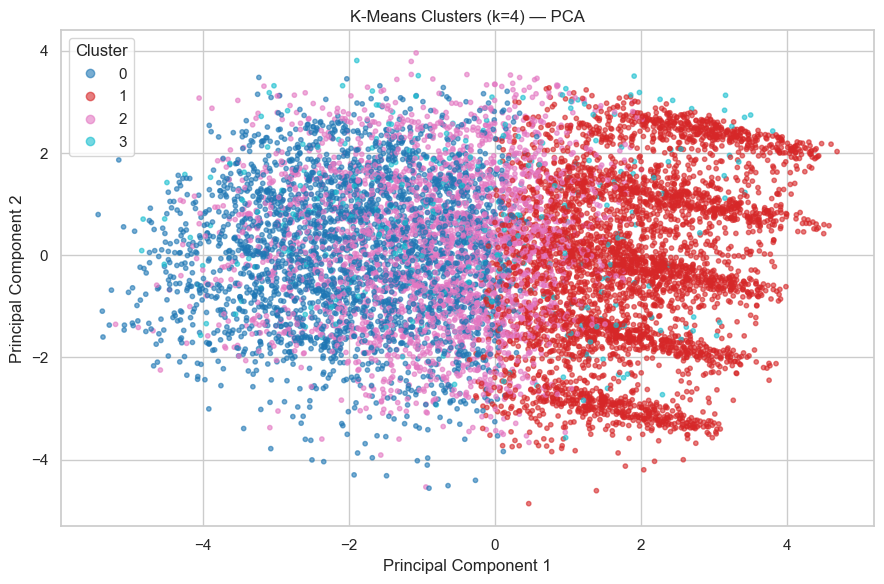

In [16]:
# Create a scatter plot with points colored by their cluster assignment
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="tab10",
    s=10,
    alpha=0.6
)

# Add title and axis labels
plt.title(f"K-Means Clusters (k={BEST_K}) — PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

# Display a legend identifying each cluster
plt.legend(*scatter.legend_elements(), title="Cluster")

# Display the graph
plt.tight_layout()
plt.show()

In [17]:
# Store results from different random initializations
sensitivity_results = []

# Test several random seeds using the same number of clusters
for seed in [0, 21, 42, 100]:

    # Create a K-Means model with the current random seed
    model = KMeans(
        n_clusters=BEST_K,
        random_state=seed,
        n_init=10
    )

    # Fit the model and obtain cluster labels
    labels = model.fit_predict(X_sample)

    # Store inertia and silhouette score
    sensitivity_results.append({
        "Random State": seed,
        "Inertia": model.inertia_,
        "Silhouette Score": silhouette_score(X_sample, labels)
    })

# Convert the results into a DataFrame
sensitivity_df = pd.DataFrame(sensitivity_results)

# Display the comparison table
display(sensitivity_df.round(4))

,Random State,Inertia,Silhouette Score
0,0,178382.9735,0.1175
1,21,179327.5469,0.0924
2,42,178383.0745,0.1176
3,100,178383.1119,0.1176


In [18]:
# Retrieve the metrics corresponding to the chosen cluster count
best_row = kmeans_results[
    kmeans_results["K"] == BEST_K
]

# Display the final comparison row if the chosen k was tested
if not best_row.empty:
    print("Final K-Means Summary")
    display(best_row.round(4))
else:
    print("Selected K was not included in the comparison table.")

Final K-Means Summary


,K,Inertia,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
2,4,178383.0745,0.1176,2.3495,967.4201


In [19]:
# Verify the data used for clustering

print("Sample shape:", X_sample.shape)
print("Number of clusters in K-Means:", BEST_K)
print("Satisfaction column available:", "satisfaction" in df.columns)

print("All values are finite:", np.isfinite(X_sample).all())

Sample shape: (10000, 23)
Number of clusters in K-Means: 4
Satisfaction column available: True
All values are finite: True


__Kmeans Baseline for Fair Comparison__

In [20]:
# Evaluate the existing K-Means model

kmeans_silhouette = silhouette_score(
    X_sample, kmeans_labels
)

kmeans_db = davies_bouldin_score(
    X_sample, kmeans_labels
)

kmeans_ch = calinski_harabasz_score(
    X_sample, kmeans_labels
)

print("K-Means Baseline")
print("Silhouette Score:", round(kmeans_silhouette, 4))
print("Davies-Bouldin Index:", round(kmeans_db, 4))
print("Calinski-Harabasz Score:", round(kmeans_ch, 4))

K-Means Baseline
Silhouette Score: 0.1176
Davies-Bouldin Index: 2.3495
Calinski-Harabasz Score: 967.4201


__Agglomerative Clustering and Dendrogram__

In [21]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage, dendrogram

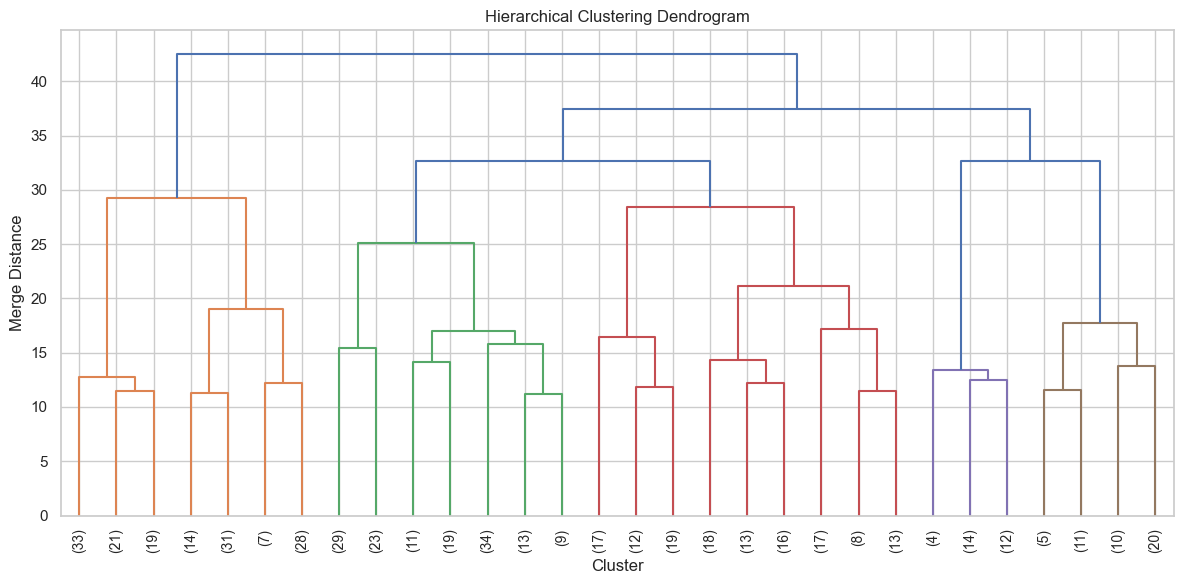

In [22]:
# Use a smaller sample to generate the dendrogram
DENDROGRAM_SIZE = min(500, len(X_sample))

X_dendrogram = X_sample[:DENDROGRAM_SIZE]

# Perform hierarchical linkage
Z = linkage(
    X_dendrogram,
    method="ward"
)

# Plot the dendrogram
plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster")
plt.ylabel("Merge Distance")

plt.tight_layout()
plt.show()
plt.show()

In [23]:
# Use the same number of clusters as K-Means
hierarchical_model = AgglomerativeClustering(
    n_clusters=BEST_K,
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(
    X_sample
)

print("Agglomerative Clustering Completed")

print("\nCluster Sizes:")
print(
    pd.Series(hierarchical_labels)
    .value_counts()
    .sort_index()
)

Agglomerative Clustering Completed

Cluster Sizes:
0    4314
1    3433
2    1666
3     587
Name: count, dtype: int64


__Linkage Strategy Comparison__

In [24]:
linkage_methods = [
    "single",
    "complete",
    "average",
    "ward"
]

linkage_results = []

for method in linkage_methods:

    model = AgglomerativeClustering(
        n_clusters=BEST_K,
        linkage=method
    )

    labels = model.fit_predict(X_sample)

    silhouette = silhouette_score(
        X_sample, labels
    )

    db_index = davies_bouldin_score(
        X_sample, labels
    )

    ch_score = calinski_harabasz_score(
        X_sample, labels
    )

    linkage_results.append({
        "Linkage": method,
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": db_index,
        "Calinski-Harabasz Score": ch_score
    })

linkage_df = pd.DataFrame(linkage_results)

display(linkage_df.round(4))

,Linkage,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,single,0.4892,0.2790,28.9522
1,complete,0.3907,0.8830,150.4797
2,average,0.4169,0.7864,132.3435
3,ward,0.0981,2.5269,763.3645


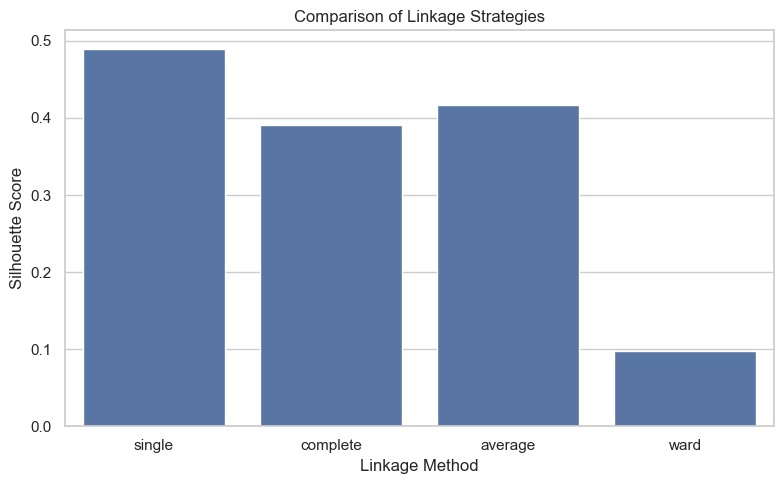

In [25]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=linkage_df,
    x="Linkage",
    y="Silhouette Score"
)

plt.title("Comparison of Linkage Strategies")
plt.xlabel("Linkage Method")
plt.ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [26]:
best_linkage = linkage_df.loc[
    linkage_df["Silhouette Score"].idxmax(),
    "Linkage"
]

print("Selected linkage:", best_linkage)

Selected linkage: single


__Silhouette, Davies–Bouldin and Calinski–Harabasz Metrics__

In [27]:
# Fit the selected hierarchical model
best_hierarchical_model = AgglomerativeClustering(
    n_clusters=BEST_K,
    linkage=best_linkage
)

best_hierarchical_labels = (
    best_hierarchical_model.fit_predict(X_sample)
)

# Evaluate hierarchical clustering
hierarchical_silhouette = silhouette_score(
    X_sample, best_hierarchical_labels
)

hierarchical_db = davies_bouldin_score(
    X_sample, best_hierarchical_labels
)

hierarchical_ch = calinski_harabasz_score(
    X_sample, best_hierarchical_labels
)

# Create the final comparison table
final_results = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Agglomerative Clustering"
    ],
    "Silhouette Score": [
        kmeans_silhouette,
        hierarchical_silhouette
    ],
    "Davies-Bouldin Index": [
        kmeans_db,
        hierarchical_db
    ],
    "Calinski-Harabasz Score": [
        kmeans_ch,
        hierarchical_ch
    ]
})

display(final_results.round(4))

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,K-Means,0.1176,2.3495,967.4201
1,Agglomerative Clustering,0.4892,0.2790,28.9522


__PCA and t-SNE Visualizations__

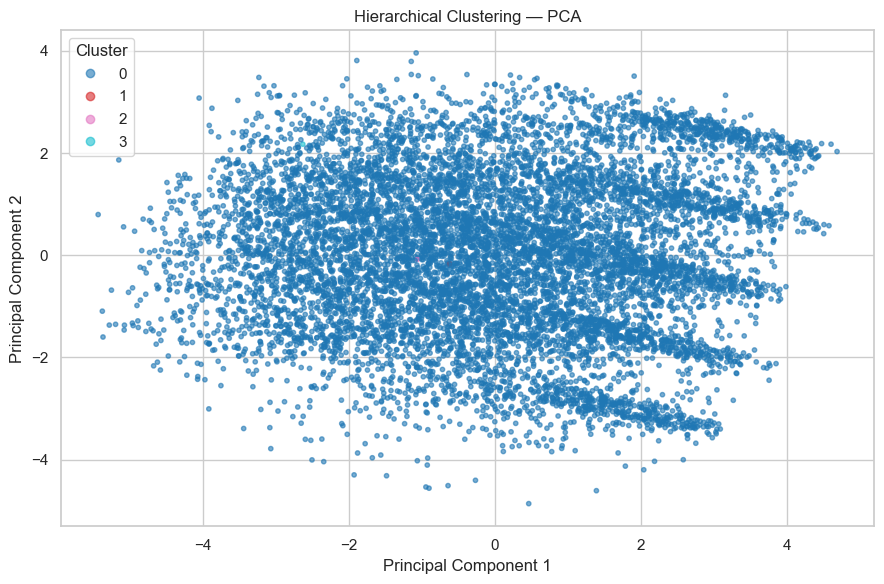

In [28]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=best_hierarchical_labels,
    cmap="tab10",
    s=10,
    alpha=0.6
)

plt.title("Hierarchical Clustering — PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(
    *scatter.legend_elements(),
    title="Cluster"
)

plt.tight_layout()
plt.show()

In [29]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_sample)

print("t-SNE completed")
print("Output shape:", X_tsne.shape)

t-SNE completed
Output shape: (10000, 2)


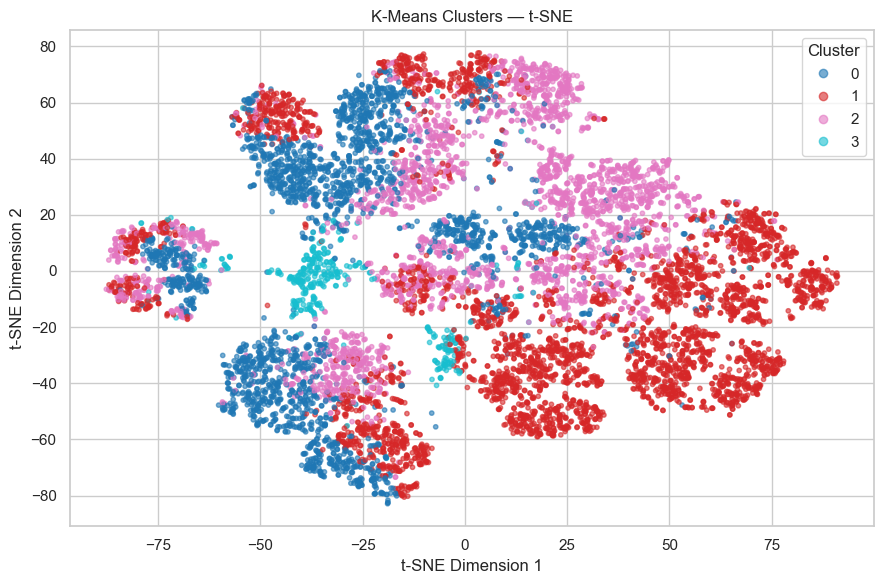

In [30]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=kmeans_labels,
    cmap="tab10",
    s=10,
    alpha=0.6
)

plt.title("K-Means Clusters — t-SNE")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")

plt.legend(
    *scatter.legend_elements(),
    title="Cluster"
)

plt.tight_layout()
plt.show()

In [41]:
import pandas as pd

print(pd.Series(kmeans_labels).value_counts().sort_index())

0    2709
1    4097
2    2821
3     373
Name: count, dtype: int64


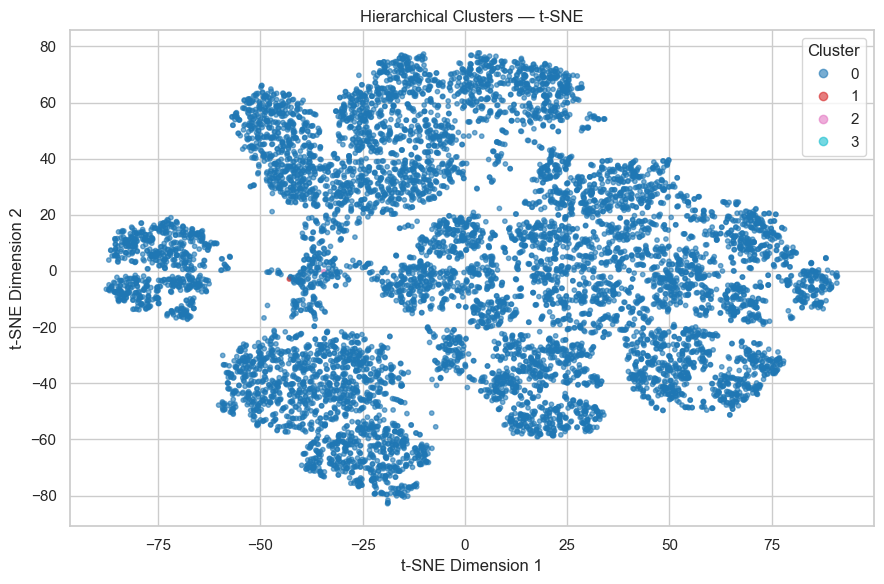

In [31]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=best_hierarchical_labels,
    cmap="tab10",
    s=10,
    alpha=0.6
)

plt.title("Hierarchical Clusters — t-SNE")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")

plt.legend(
    *scatter.legend_elements(),
    title="Cluster"
)

plt.tight_layout()
plt.show()

In [40]:

import pandas as pd

print(pd.Series(best_hierarchical_labels).value_counts().sort_index())

0    9997
1       1
2       1
3       1
Name: count, dtype: int64


__Cluster Profiles, Satisfaction Validation and Conclusions__

In [32]:
# Retrieve the original passenger records for the sample
profile_data = df.iloc[sample_indices].copy()

profile_data = profile_data.reset_index(drop=True)

# Add the hierarchical cluster labels
profile_data["Cluster"] = best_hierarchical_labels

# Select numerical columns
numeric_columns = profile_data.select_dtypes(
    include=np.number
).columns.tolist()

# Exclude identifier columns
numeric_columns = [
    col for col in numeric_columns
    if col not in ["Unnamed: 0", "id"]
]

# Calculate the average numerical values by cluster
cluster_profiles = profile_data.groupby(
    "Cluster"
)[numeric_columns].mean()

# Add the number of passengers in each cluster
cluster_profiles["Passenger Count"] = (
    profile_data.groupby("Cluster").size()
)

display(cluster_profiles.round(2))

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Cluster,Passenger Count
Cluster,,,,,,,,,,,,,,,,,,,,
0,39.59,1205.59,2.73,3.06,2.75,2.98,3.21,3.24,3.45,3.36,3.38,3.35,3.63,3.3,3.62,3.28,14.95,15.3,0.0,9997
1,49.00,1959.00,1.00,1.00,1.00,1.00,4.00,4.00,4.00,4.00,4.00,4.00,5.00,4.0,4.00,4.00,1017.00,1011.0,1.0,1
2,50.00,95.00,1.00,3.00,3.00,3.00,4.00,1.00,3.00,4.00,3.00,4.00,4.00,3.0,2.00,3.00,455.00,NaN,2.0,1
3,64.00,1956.00,2.00,5.00,2.00,4.00,2.00,1.00,1.00,5.00,3.00,3.00,5.00,1.0,4.00,1.00,570.00,567.0,3.0,1


In [33]:
if "satisfaction" in profile_data.columns:

    satisfaction_counts = pd.crosstab(
        profile_data["Cluster"],
        profile_data["satisfaction"]
    )

    print("Satisfaction Counts by Cluster")

    display(satisfaction_counts)

else:
    print("Satisfaction column not found.")

Satisfaction Counts by Cluster


satisfaction,neutral or dissatisfied,satisfied
Cluster,,
0,5679,4318
1,0,1
2,1,0
3,1,0


In [34]:
if "satisfaction" in profile_data.columns:

    satisfaction_percentages = pd.crosstab(
        profile_data["Cluster"],
        profile_data["satisfaction"],
        normalize="index"
    ) * 100

    print("Satisfaction Percentages by Cluster")

    display(satisfaction_percentages.round(2))

Satisfaction Percentages by Cluster


satisfaction,neutral or dissatisfied,satisfied
Cluster,,
0,56.81,43.19
1,0.00,100.00
2,100.00,0.00
3,100.00,0.00


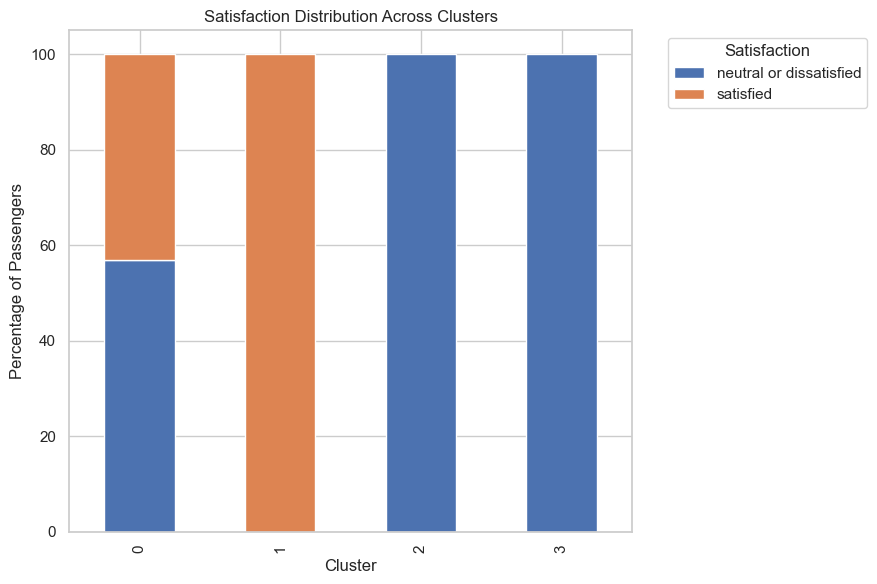

In [35]:
if "satisfaction" in profile_data.columns:

    satisfaction_percentages.plot(
        kind="bar",
        stacked=True,
        figsize=(9, 6)
    )

    plt.title("Satisfaction Distribution Across Clusters")
    plt.xlabel("Cluster")
    plt.ylabel("Percentage of Passengers")

    plt.legend(
        title="Satisfaction",
        bbox_to_anchor=(1.05, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

__Final evaluation summary__

In [36]:
print("=" * 60)
print("FINAL CLUSTERING EVALUATION")
print("=" * 60)

print("\nNumber of clusters:", BEST_K)
print("Selected linkage:", best_linkage)

print("\nK-Means:")
print("Silhouette:", round(kmeans_silhouette, 4))
print("Davies-Bouldin:", round(kmeans_db, 4))
print("Calinski-Harabasz:", round(kmeans_ch, 4))

print("\nHierarchical Clustering:")
print("Silhouette:", round(hierarchical_silhouette, 4))
print("Davies-Bouldin:", round(hierarchical_db, 4))
print("Calinski-Harabasz:", round(hierarchical_ch, 4))

print("\nCluster Sizes:")
print(
    profile_data["Cluster"]
    .value_counts()
    .sort_index()
)

print("\nFinal Comparison:")
display(final_results.round(4))

FINAL CLUSTERING EVALUATION

Number of clusters: 4
Selected linkage: single

K-Means:
Silhouette: 0.1176
Davies-Bouldin: 2.3495
Calinski-Harabasz: 967.4201

Hierarchical Clustering:
Silhouette: 0.4892
Davies-Bouldin: 0.279
Calinski-Harabasz: 28.9522

Cluster Sizes:
Cluster
0    9997
1       1
2       1
3       1
Name: count, dtype: int64

Final Comparison:


,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,K-Means,0.1176,2.3495,967.4201
1,Agglomerative Clustering,0.4892,0.2790,28.9522


In [37]:
if hierarchical_silhouette > kmeans_silhouette:
    print(
        "Hierarchical Clustering has a higher "
        "Silhouette Score than K-Means."
    )
else:
    print(
        "K-Means has an equal or higher "
        "Silhouette Score than Hierarchical Clustering."
    )

if hierarchical_db < kmeans_db:
    print(
        "Hierarchical Clustering has a lower "
        "Davies-Bouldin Index."
    )
else:
    print(
        "K-Means has an equal or lower "
        "Davies-Bouldin Index."
    )

if hierarchical_ch > kmeans_ch:
    print(
        "Hierarchical Clustering has a higher "
        "Calinski-Harabasz Score."
    )
else:
    print(
        "K-Means has an equal or higher "
        "Calinski-Harabasz Score."
    )

Hierarchical Clustering has a higher Silhouette Score than K-Means.
Hierarchical Clustering has a lower Davies-Bouldin Index.
K-Means has an equal or higher Calinski-Harabasz Score.
